AI VISION LAB · 6–7강 통합 프로젝트

MISSION 03

# 나만의 특성을 설계하고
검증하기

가설을 세우고, 직접 설계하고, 실험으로 확인하기

권장 학습 시간 · 약 5시간실습 환경 · Google Colab데이터 · LSWMD_labeled.pkl / wafer_features.pkl

## 이번 미션에서 해결할 문제

지금까지 우리는 웨이퍼맵에서 두 가지 특성을 추출했습니다.

- **defect_ratio:** 웨이퍼 전체의 불량률
- **edge_ratio:** 웨이퍼 가장자리 영역의 불량률

미션 02에서는 불량률만 사용한 모델 A와 가장자리 불량률을 추가한 모델 B를 학습하고 성능을 비교했습니다.

이 실험을 통해 사람이 직접 설계한 특성이 불량 패턴을 구분하는 데 도움이 될 수도 있고, 예상과 달리 성능을 개선하지 못할 수도 있다는 점을 확인했습니다.

그렇다면 여러분이 직접 새로운 특성을 설계한다면 어떨까요?

이번 미션에서는 **자신이 선택한 특성을 구현하고, 분류 모델에 추가하여 그 효과를 검증**합니다.

단순히 성능이 높은 모델을 만드는 것이 목표는 아닙니다. 어떤 특성이 유용할 것이라는 가설을 세우고, 실험을 통해 그 가설을 확인하는 것이 더 중요합니다.

이번 미션을 완료하면 다음을 할 수 있습니다.

- 불량 패턴을 구분하는 데 도움이 될 특성을 제안할 수 있습니다.
- 웨이퍼맵 배열에서 새로운 특성을 계산하는 함수를 구현할 수 있습니다.
- 기존 특성에 새로운 특성을 추가하여 분류 모델을 학습할 수 있습니다.
- 동일한 조건에서 특성 추가 전후의 성능을 비교할 수 있습니다.
- 실험 결과를 해석하고 그 과정과 결론을 보고서로 작성할 수 있습니다.

이번 미션은 6~7강 특성공학 프로젝트의 마지막 단계이며, **중간고사 대체 보고서 작성까지 포함**합니다.

**질문과 보고서 안내**

워크북의 모든 질문에 답할 필요는 없습니다. **[필수 기록]** 질문을 중심으로 실험 결과와 분석 내용을 보고서에 정리하세요.

## 알아두기. 좋은 특성이란 무엇일까?

### 1. 특성이 많으면 모델 성능이 좋아질까?

우리는 이미 두 가지 특성을 추출했습니다.

그렇다면 여기에 새로운 특성을 계속 추가하면 분류 성능도 계속 좋아질까요?

반드시 그렇지는 않습니다.

어떤 특성은 불량 유형을 구분하는 데 중요한 정보를 제공하지만, 어떤 특성은 기존 특성과 비슷한 정보를 나타내거나 분류에 별 도움이 되지 않을 수 있습니다.

예를 들어 다음 두 특성을 생각해 봅시다.

- 전체 불량 칩의 개수
- 전체 유효 칩 중 불량 칩의 비율

웨이퍼맵의 크기와 유효 칩 수가 같다면 두 특성은 매우 비슷한 정보를 제공할 것입니다.

반면 다음 두 특성은 서로 다른 정보를 제공할 가능성이 있습니다.

- 전체 불량률
- 불량이 위쪽과 아래쪽 중 어느 곳에 집중되어 있는지를 나타내는 값

두 웨이퍼의 전체 불량률이 같더라도 불량의 위치는 다를 수 있기 때문입니다.

따라서 새로운 특성을 설계할 때는 다음 질문을 생각해 보아야 합니다.

**"이 특성은 기존 특성에 없는 어떤 정보를 제공하는가?"**

### 2. 특성 설계에는 도메인 지식이 필요하다

웨이퍼맵의 불량 유형을 다시 떠올려 봅시다.

| 불량 유형 | 주요 패턴 특징 | 생각해 볼 특성 |
| --- | --- | --- |
| Center | 중심 부근에 불량 집중 | 중앙 영역 불량률 |
| Edge-Ring | 가장자리를 따라 불량 분포 | 가장자리 불량률 |
| Edge-Loc | 가장자리의 일부 영역에 불량 집중 | 영역별 불량률 차이 |
| Loc | 특정 영역에 불량 집중 | 불량 중심 좌표, 연결 영역 크기 |
| Scratch | 선 형태로 불량 분포 | 불량의 방향성, 길게 연결된 영역 |
| Random | 여러 위치에 불량 분산 | 불량의 분산 정도 |
| Donut | 고리 모양의 불량 분포 | 중심에서의 거리별 불량률 |
| Near-full | 웨이퍼 대부분에 불량 발생 | 전체 불량률 |

위 표는 특성 설계를 위한 아이디어입니다. 특정 특성이 실제로 해당 유형을 잘 구분한다는 뜻은 아닙니다.

예를 들어 Scratch는 선 형태의 불량 패턴이지만, 단순히 불량의 방향성을 계산했다고 해서 모든 Scratch를 구분할 수 있는 것은 아닙니다.

**도메인 지식은 좋은 특성을 생각해 내는 출발점이며, 실제 유용성은 실험으로 검증해야 합니다.**

## 활동 A. 나만의 특성 설계하기

### 1. 기존 실험 결과 다시 살펴보기

미션 02에서 모델 B는 다음 두 특성을 사용했습니다.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 이전 미션의 특성 데이터를 불러와 독립적으로 실행합니다.
data_dir = Path.cwd()
if not (data_dir / 'wafer_features.pkl').is_file():
    data_dir = Path('D:\\2604340036 - 송성민\\2학기\\반도체장비AI비전실무\\2026-AIVISION_06강')
df = pd.read_pickle(data_dir / 'wafer_features.pkl')

X_B = df[['defect_ratio', 'edge_ratio']]

그런데 이 두 특성만으로 구분하기 어려운 불량 유형도 있었을 것입니다.

미션 02의 혼동행렬과 클래스별 성능을 다시 살펴보세요.

**Q1.**필수 기록

모델 B에서 상대적으로 구분하기 어려웠던 불량 유형은 무엇인가요? 혼동행렬이나 Recall, F1-score를 근거로 설명해 보세요.

**답변:**

**Scratch**가 Recall 약 **21.43%, F1 약 0.2406**으로 가장 어려웠습니다. **Donut**도 Recall 약 **33.33%, F1 약 0.3507**로 낮았습니다.

**Q2.**

기존의 `defect_ratio`와 `edge_ratio`만으로 해당 불량 유형을 구분하기 어려운 이유는 무엇이라고 생각하나요?

예를 들어 불량이 한쪽에 집중된 Loc 패턴과 불량이 선 형태로 이어지는 Scratch 패턴은 전체 불량률이나 가장자리 불량률이 비슷할 수도 있습니다.

그러나 불량 칩들이 공간적으로 분포하는 모습은 다릅니다.

이러한 차이를 숫자로 표현할 수 있다면 새로운 특성이 될 수 있습니다.

**답변:**

두 특성은 전체와 가장자리의 불량 비율만 나타냅니다. **불량의 선·고리·군집 모양과 중앙 집중 정도**를 충분히 표현하지 못하기 때문입니다.

### 2. 새로운 특성 후보 살펴보기

다음은 웨이퍼맵에서 만들 수 있는 특성의 예시입니다.

| 특성 | 의미 | 구현 난이도 |
| --- | --- | --- |
| 상하 불량률 차이 | 위쪽과 아래쪽의 불량률 차이 | 쉬움 |
| 좌우 불량률 차이 | 왼쪽과 오른쪽의 불량률 차이 | 쉬움 |
| 중앙 영역 불량률 | 웨이퍼 중심 부근의 불량률 | 보통 |
| 불량 중심 좌표 | 불량 칩들이 집중된 평균 위치 | 보통 |
| 불량 분포의 퍼짐 정도 | 불량 칩들이 얼마나 넓게 분산되어 있는가 | 보통 |
| 최대 연결 불량 영역 | 서로 연결된 불량 칩들의 최대 영역 크기 | 어려움 |
| 불량 분포의 방향성 | 불량이 특정 방향으로 길게 분포하는 정도 | 어려움 |

위의 후보 중 하나를 선택해도 되고, 새로운 특성을 직접 제안해도 됩니다.

단, 이번 실습에서는 **새로운 특성 하나를 완성하는 것**을 우선 목표로 합니다.

여러 특성을 추가하는 것보다 자신이 선택한 특성이 어떤 의미를 가지며, 실제로 어떤 영향을 주었는지 이해하는 것이 중요합니다.

### 3. 특성 설계서 작성하기

코드를 작성하기 전에 자신의 아이디어를 먼저 정리해 보세요.

**Q3.**필수 기록

나만의 특성 설계서

다음 항목을 작성하세요.

| 항목 | 작성 내용 |
| --- | --- |
| 특성 이름 | 새롭게 만들 특성의 이름 |
| 특성이 나타내는 정보 | 어떤 공간적·수치적 특징을 표현하는가? |
| 대상 불량 유형 | 어떤 불량 유형을 구분하는 데 도움이 될 것으로 예상하는가? |
| 선택한 이유 | 기존 특성으로 표현하기 어려운 어떤 정보를 추가하는가? |
| 계산 방법 | 웨이퍼맵 배열에서 어떤 값을 계산할 것인가? |

마지막으로 자신의 예상 결과를 한 문장으로 작성해 보세요.

**가설:** "__________ 특성을 추가하면 __________ 불량 유형의 분류 성능이 개선될 것이다."

이 가설이 반드시 맞을 필요는 없습니다.

실험 결과를 확인한 후 자신의 예상이 맞았는지 검토하면 됩니다.

**답변:**

- **특성 이름:** 중앙 영역 불량률(`center_defect_ratio`)입니다. 모델에서는 `my_feature` 열로 사용합니다.
- **나타내는 정보:** 중앙 유효 칩 중 불량 칩의 비율입니다.
- **대상 불량 유형:** Center와 Edge-Ring입니다.
- **선택 이유:** 기존 특성에 없는 중앙 집중 정보를 추가하기 위해서입니다.
- **계산 방법:** 중심에서 최대 거리의 40% 이내인 유효 영역의 불량 칩 수를 해당 영역의 유효 칩 수로 나눕니다. 해당 칩이 없으면 0을 반환합니다.

**가설:** 중앙 영역 불량률을 추가하면 Center와 Edge-Ring의 분류 성능이 개선될 것입니다.

## 활동 B. 새로운 특성을 구현하기

### 1. 실습 데이터 준비하기

미션 01에서 사용했던 `LSWMD_labeled.pkl` 파일과 `wafer_features.pkl` 파일을 모두 사용합니다.

- `LSWMD_labeled.pkl`: 원본 웨이퍼맵 배열이 저장된 데이터
- `wafer_features.pkl`: 미션 01에서 추출한 두 특성이 저장된 데이터

새로운 특성을 계산하려면 원본 웨이퍼맵 배열이 필요합니다.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# VS Code에서는 Google Drive 연결 대신 로컬 폴더를 사용합니다.

data_path = str(data_dir) + '/'

original_df = pd.read_pickle(
    data_path + 'LSWMD_labeled.pkl'
)

feature_df = pd.read_pickle(
    data_path + 'wafer_features.pkl'
)

print("원본 데이터:", original_df.shape)
print("특성 데이터:", feature_df.shape)

display(feature_df.head())

,failureType_clean,defect_ratio,edge_ratio
0,Loc,0.086750,0.111940
1,Edge-Loc,0.089024,0.170667
2,Edge-Loc,0.097154,0.173333
3,Edge-Loc,0.109756,0.222667
4,Edge-Loc,0.111382,0.221333


원본 데이터: (25519, 9)
특성 데이터: (25519, 3)


두 파일은 미션 01에서 동일한 데이터와 행 순서를 이용해 생성했습니다.

새로운 특성을 추가할 때도 각 웨이퍼맵과 불량 유형의 대응 관계가 유지되어야 합니다.

다음 코드는 두 데이터의 행 개수와 라벨 순서를 확인합니다.

In [3]:
same_length = len(original_df) == len(feature_df)

same_labels = (
    original_df['failureType_clean']
    .reset_index(drop=True)
    .equals(
        feature_df['failureType_clean']
        .reset_index(drop=True)
    )
)

print("행 개수 일치:", same_length)
print("라벨 순서 일치:", same_labels)

if not (same_length and same_labels):
    raise ValueError(
        "두 파일의 데이터 순서를 확인하세요."
    )

행 개수 일치: True
라벨 순서 일치: True


두 결과가 모두 `True`인 경우에만 다음 단계로 진행하세요.

이 검사는 데이터가 올바르게 연결되었는지 확인하는 기본 점검입니다. 라벨 순서가 같더라도 모든 원본 배열의 대응 관계까지 완전히 검증하는 것은 아니므로, 미션 01에서 저장한 파일을 그대로 사용하는 것이 중요합니다.

### 2. 특성 추출 함수 예제 살펴보기

이번에는 **상하 불량률 차이**를 계산하는 함수를 예제로 살펴보겠습니다.

웨이퍼맵의 위쪽과 아래쪽에서 각각 불량률을 계산한 뒤 두 값의 차이를 구하는 방식입니다.

상하 불량률 차이 = 상단 불량률 − 하단 불량률

예를 들어 상단 불량률이 0.30이고 하단 불량률이 0.10이라면 특성값은 0.20입니다.

반대로 하단 불량률이 더 높다면 음수가 나옵니다.

- 양수: 위쪽의 불량률이 더 높음
- 0에 가까움: 위쪽과 아래쪽의 불량률이 비슷함
- 음수: 아래쪽의 불량률이 더 높음

다음 코드를 읽고 실행해 보세요.

In [4]:
def top_bottom_difference(wafer_map):
    wafer_map = np.asarray(wafer_map)

    h = wafer_map.shape[0]
    mid = h // 2

    # 웨이퍼맵을 위쪽과 아래쪽으로 분리
    top = wafer_map[:mid, :]
    bottom = wafer_map[mid:, :]

    # 유효 칩 개수
    top_valid = np.sum(top != 0)
    bottom_valid = np.sum(bottom != 0)

    # 불량 칩 개수
    top_defect = np.sum(top == 2)
    bottom_defect = np.sum(bottom == 2)

    # 각 영역의 불량률
    top_ratio = (
        top_defect / top_valid
        if top_valid > 0 else 0.0
    )

    bottom_ratio = (
        bottom_defect / bottom_valid
        if bottom_valid > 0 else 0.0
    )

    return top_ratio - bottom_ratio

이 함수는 미션 01에서 사용했던 `defect_ratio()`와 비슷한 계산을 수행합니다.

차이점은 웨이퍼맵 전체가 아니라 두 영역을 나누어 계산한다는 것입니다.

**Q4.**

`wafer_map[:mid, :]`와 `wafer_map[mid:, :]`는 각각 배열의 어느 부분을 선택하나요?

**답변:**

`wafer_map[:mid, :]`는 **위쪽 절반의 모든 열**, `wafer_map[mid:, :]`는 **아래쪽 절반의 모든 열**을 선택합니다. 행 수가 홀수이면 가운데 행은 아래쪽에 포함됩니다.

**Q5.**

`top_ratio - bottom_ratio` 대신 `abs(top_ratio - bottom_ratio)`를 사용하면 특성의 의미가 어떻게 달라질까요?

두 계산 방식 중 어느 것이 더 유용할지는 구분하려는 패턴에 따라 달라질 수 있습니다.

예를 들어 단순히 상하 불균형의 크기를 표현하려면 절댓값이 유용하지만, 불량이 어느 방향에 집중되었는지까지 표현하려면 부호를 유지하는 편이 좋을 수 있습니다.

**답변:**

원래 계산은 **어느 쪽의 불량률이 높은지와 차이의 크기**를 나타냅니다. 절댓값을 사용하면 방향 정보가 사라지고 **상하 불균형의 크기**만 남습니다.

### 3. 나만의 특성 함수 만들기

이제 자신이 선택한 특성을 구현해 보세요.

**특성은 자유롭게 선택할 수 있습니다.** 활동 A의 '새로운 특성 후보 살펴보기'에서 제시한 특성 중 하나를 선택해도 되고, 자신만의 새로운 특성을 직접 제안해도 됩니다.

다음은 특성을 구현할 수 있는 방법의 예시입니다. **반드시 아래 방법 중 하나를 선택해야 하는 것은 아닙니다.**

- 제공된 `top_bottom_difference()` 함수를 그대로 사용합니다.
- 예제 함수를 수정하여 좌우 불량률 차이 등의 특성을 만듭니다.
- 미션 01의 `edge_defect_ratio()`를 참고하여 중앙 영역 불량률을 계산합니다.
- 새로운 계산 방법을 직접 설계하여 함수를 만듭니다.

예제 함수를 선택해도 괜찮습니다. 다만 특성을 선택한 이유와 그 특성이 가지는 의미를 설명할 수 있어야 합니다.

**실습 시 주의할 점**

1. 입력은 하나의 웨이퍼맵 배열이어야 합니다.
2. 결과는 모델의 입력에 사용할 수 있는 숫자값이어야 합니다.
3. 유효하지 않은 칩 영역을 계산에 적절히 반영해야 합니다.
4. 0으로 나누는 상황이나 불량 칩이 없는 경우를 고려해야 합니다.
5. 모든 웨이퍼맵에 동일한 계산 기준을 적용해야 합니다.

다음은 예제 함수를 개인 특성으로 선택한 경우의 코드입니다.

다른 특성을 구현했다면 함수 이름을 자신이 만든 함수로 변경하세요.

In [5]:
# 미션 01에서 제안한 중앙 영역 불량률을 구현합니다.
def center_defect_ratio(wafer_map):
    wafer_map = np.asarray(wafer_map)
    valid = wafer_map != 0
    if not np.any(valid):
        return 0.0

    y, x = np.indices(wafer_map.shape)
    cy = y[valid].mean()
    cx = x[valid].mean()
    distance = np.sqrt((y - cy)**2 + (x - cx)**2)
    max_distance = distance[valid].max()

    # 최대 거리의 40% 이내인 유효 칩을 중앙 영역으로 정의합니다.
    center = valid & (distance <= max_distance * 0.4)
    center_count = np.sum(center)
    if center_count == 0:
        return 0.0
    return np.sum((wafer_map == 2) & center) / center_count

# 사용할 특성 추출 함수를 지정
my_feature_function = center_defect_ratio

# 원본 웨이퍼맵에서 개인 특성 추출
my_feature_values = (
    original_df['waferMap']
    .apply(my_feature_function)
)

# 특성 데이터프레임에 새로운 열 추가
feature_df['my_feature'] = (
    my_feature_values.to_numpy()
)

display(feature_df.head())

,failureType_clean,defect_ratio,edge_ratio,my_feature
0,Loc,0.086750,0.111940,0.048951
1,Edge-Loc,0.089024,0.170667,0.047170
2,Edge-Loc,0.097154,0.173333,0.063679
3,Edge-Loc,0.109756,0.222667,0.070755
4,Edge-Loc,0.111382,0.221333,0.040094


`my_feature`는 모델 학습에 사용할 새로운 열의 이름입니다.

학생마다 서로 다른 특성을 선택하더라도 이후 모델 학습 코드에서는 동일한 열 이름을 사용할 수 있도록 했습니다.

### 4. 특성값이 올바르게 계산되었는지 확인하기

새로운 함수를 만들었다면 결과를 확인해야 합니다.

In [6]:
print("특성값 범위:")
print(feature_df['my_feature'].min())
print(feature_df['my_feature'].max())

print("\n특성값 요약:")
display(
    feature_df['my_feature'].describe()
)

print(
    "유한한 숫자로 계산되었는가?",
    np.isfinite(
        feature_df['my_feature'].to_numpy()
    ).all()
)

count    25519.000000
mean         0.180356
std          0.205600
min          0.000000
25%          0.045283
50%          0.091892
75%          0.232558
max          1.000000
Name: my_feature, dtype: float64

특성값 범위:
0.0
1.0

특성값 요약:
유한한 숫자로 계산되었는가? True


특성값의 예상 범위는 계산 방법에 따라 달라집니다.

예를 들어 상하 불량률 차이는 -1에서 1 사이의 값이지만, 불량 칩의 개수를 직접 계산한 특성이라면 훨씬 큰 값이 나올 수도 있습니다.

특성의 계산 방법에 따라 예상 가능한 값의 범위를 먼저 생각해 보세요.

**Q6.**

자신이 만든 특성의 값은 어떤 범위에 있어야 할까요? 실제 계산 결과가 예상 범위에 들어 있는지 확인해 보세요.

**답변:**

중앙 영역 불량률은 **0~1** 범위여야 합니다. 실제 최솟값은 **0**, 최댓값은 **1**이며 모든 값이 유한한 숫자로 계산되었습니다.

### 5. 특성값의 분포 확인하기

모델에 특성을 입력하기 전에 불량 유형에 따라 특성값이 어떻게 나타나는지 살펴보겠습니다.

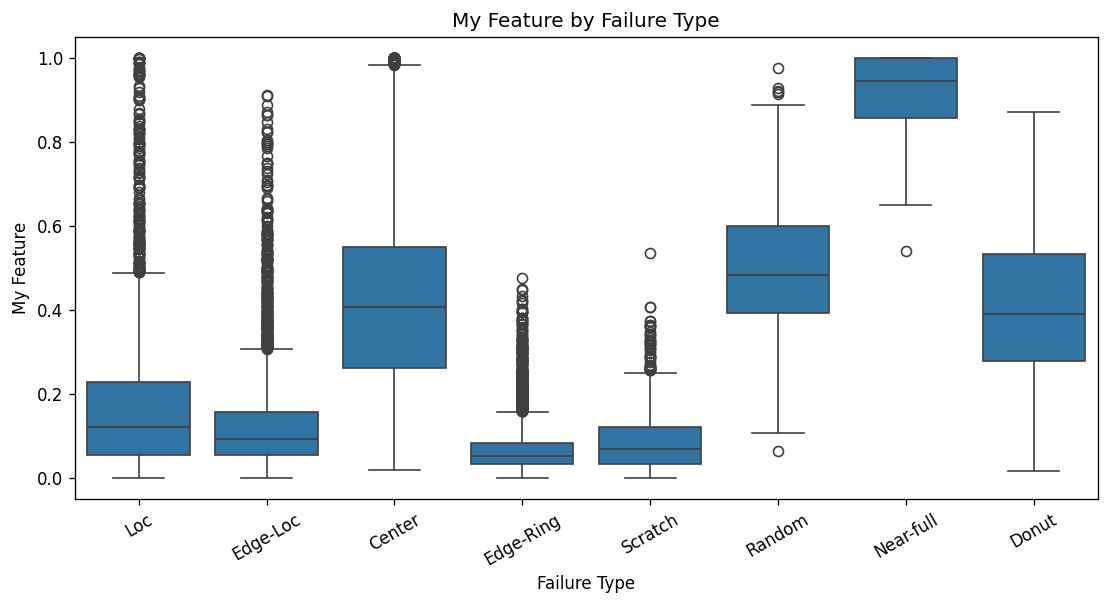

In [7]:
plt.figure(figsize=(11, 5))

sns.boxplot(
    data=feature_df,
    x='failureType_clean',
    y='my_feature'
)

plt.xticks(rotation=30)
plt.title('My Feature by Failure Type')
plt.xlabel('Failure Type')
plt.ylabel('My Feature')
plt.show()

이 그래프는 각 불량 유형에서 새로운 특성의 값이 어떻게 분포하는지 보여줍니다.

특정 유형에서 값이 높거나 낮게 나타난다면 해당 유형을 구분하는 데 도움이 될 가능성이 있습니다.

반대로 여러 유형에서 비슷한 분포가 나타나면 새로운 특성만으로는 구분하기 어려울 수도 있습니다.

**Q7.**필수 기록

자신이 만든 특성의 분포를 확인해 보세요.

- 어떤 불량 유형에서 특징적인 값이 나타났나요?
- 처음 예상했던 불량 유형에서 실제로 차이가 나타났나요?
- 서로 비슷한 값의 분포를 보이는 불량 유형은 무엇인가요?

그래프를 근거로 자신의 특성이 어떤 정보를 표현하는지 설명해 보세요.

**답변:**

- **특징적인 유형:** Near-full의 평균이 약 **90.94%**로 높았습니다.
- **예상한 차이:** Center는 평균 약 **42.39%**, Edge-Ring은 약 **6.55%**로 중앙 불량 비율에 차이가 있었습니다.
- **비슷한 분포:** Center와 Donut의 중앙값은 약 **40.66%, 38.89%**로 비슷하고 분포가 겹칩니다.

이 특성은 중앙의 불량 집중 정도를 나타내지만, 하나의 값만으로 모든 유형을 구분하지는 못합니다.

## 활동 C. 나만의 특성으로 모델 성능 비교하기

### 1. 비교 실험 설계

이번에는 두 모델을 비교합니다.

| 구분 | 모델 B | 모델 C |
| --- | --- | --- |
| 입력 특성 | defect_ratio, edge_ratio | defect_ratio, edge_ratio, my_feature |
| 분류 알고리즘 | RandomForest | RandomForest |
| 학습·테스트 데이터 | 동일 | 동일 |
| 난수 시드 | 42 | 42 |
| 평가 지표 | Accuracy, Macro F1 | Accuracy, Macro F1 |

모델 B는 미션 02에서 사용한 모델입니다.

모델 C는 여기에 자신이 설계한 특성을 하나 더 추가한 모델입니다.

**이번 실험에서 변경하는 조건은 개인 특성의 추가 여부입니다.**

미션 02와 같은 데이터, 같은 분할 방법, 같은 모델 설정을 사용하여 성능을 비교하겠습니다.

### 2. 데이터 분할과 모델 학습

미션 02에서 사용했던 코드를 다시 활용합니다.

다음 코드를 실행하면 동일한 데이터 순서와 시드를 기준으로 학습·테스트 데이터 분할을 다시 생성할 수 있습니다.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

RANDOM_STATE = 42

y = feature_df['failureType_clean']

train_idx, test_idx = train_test_split(
    np.arange(len(feature_df)),
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

이 코드는 미션 02와 동일한 데이터와 행 순서를 사용한다는 전제에서 같은 분할 결과를 재현합니다.

그다음 모델 B와 모델 C의 입력 특성을 준비합니다.

In [9]:
X_B = feature_df[
    ['defect_ratio', 'edge_ratio']
]

X_C = feature_df[
    ['defect_ratio', 'edge_ratio', 'my_feature']
]

X_B_train = X_B.iloc[train_idx]
X_B_test = X_B.iloc[test_idx]

X_C_train = X_C.iloc[train_idx]
X_C_test = X_C.iloc[test_idx]

이번에는 모델을 학습하고 평가하는 과정을 함수로 만들어 보겠습니다.

동일한 학습 코드를 반복하는 대신, 입력 특성만 바꾸어 사용할 수 있습니다.

In [10]:
def train_and_evaluate(X_train, X_test, y_train, y_test):
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(
        y_test, predictions
    )

    macro_f1 = f1_score(
        y_test,
        predictions,
        average='macro'
    )

    return model, predictions, accuracy, macro_f1

이 함수는 네 가지 값을 반환합니다.

- 학습이 완료된 모델
- 테스트 데이터의 예측 결과
- Accuracy
- Macro F1-score

이제 함수 하나로 두 모델을 각각 학습하고 평가합니다.

In [11]:
model_B, pred_B, acc_B, f1_B = train_and_evaluate(
    X_B_train, X_B_test, y_train, y_test
)

model_C, pred_C, acc_C, f1_C = train_and_evaluate(
    X_C_train, X_C_test, y_train, y_test
)

print(f"모델 B: Accuracy={acc_B:.4f}, Macro F1={f1_B:.4f}")
print(f"모델 C: Accuracy={acc_C:.4f}, Macro F1={f1_C:.4f}")

모델 B: Accuracy=0.6853, Macro F1=0.6020
모델 C: Accuracy=0.7461, Macro F1=0.6790


**Q8.**

`train_and_evaluate()` 함수를 사용하면 동일한 코드를 반복 작성하는 것과 비교해 어떤 장점이 있을까요?

**답변:**

반복 코드를 줄이고 **두 모델에 같은 학습·평가 조건을 적용**할 수 있습니다. 설정 변경과 오류 수정도 한곳에서 할 수 있습니다.

**Q9.**

모델 B와 C는 입력 데이터의 열 개수가 다릅니다. 그런데 학습 데이터의 행 개수와 테스트 데이터의 행 개수는 같아야 하는 이유는 무엇인가요?

**답변:**

**같은 웨이퍼로 학습하고 같은 웨이퍼로 평가해야** 특성 추가의 효과를 공정하게 비교할 수 있기 때문입니다. 행 수뿐 아니라 실제 사용한 행과 라벨도 같아야 합니다.

### 3. 성능 비교 결과 확인하기

In [12]:
results_BC = pd.DataFrame({
    'Model': [
        'B: Existing Features',
        'C: + My Feature'
    ],
    'Accuracy': [acc_B, acc_C],
    'Macro F1': [f1_B, f1_C]
})

display(results_BC.round(4))

print(f"Accuracy 변화: {acc_C - acc_B:+.4f}")
print(f"Macro F1 변화: {f1_C - f1_B:+.4f}")

,Model,Accuracy,Macro F1
0,B: Existing Features,0.6853,0.602
1,C: + My Feature,0.7461,0.679


Accuracy 변화: +0.0607
Macro F1 변화: +0.0770


결과표를 확인해 보세요.

새로운 특성을 추가한 모델 C의 성능이 더 높아졌나요?

혹은 거의 변화가 없거나 성능이 낮아졌나요?

이번에는 결과가 예상과 다르게 나타나더라도 새로운 특성을 계속 변경하면서 높은 점수를 찾을 필요는 없습니다.

우선 자신이 설계한 특성의 효과를 분석하는 데 집중하세요.

**Q10.**필수 기록

모델 B와 모델 C의 Accuracy와 Macro F1-score를 비교해 보세요.

- 두 지표는 각각 얼마나 변화했나요?
- 처음 세운 가설과 일치하는 결과가 나왔나요?
- 예상과 다른 결과가 나왔다면 어떤 이유를 생각할 수 있나요?

**답변:**

정확도는 **68.53% → 74.61%로 약 6.07%p 상승**했고, Macro F1은 **0.6020 → 0.6790으로 약 0.0770 상승**했습니다. 다만 Center의 Recall은 높아지고 Edge-Ring은 조금 낮아져, 두 유형 모두 개선될 것이라는 가설은 일부만 맞았습니다.

### 4. 클래스별 분류 결과 비교하기

전체 성능이 개선되지 않았더라도 특정 불량 유형에서는 개선이 나타났을 수 있습니다.

반대로 전체 성능이 좋아졌더라도 일부 클래스의 성능은 낮아졌을 수 있습니다.

이번에는 클래스별 Recall을 비교해 보겠습니다.

In [13]:
from sklearn.metrics import recall_score

labels = sorted(y.unique())

recall_B = recall_score(
    y_test, pred_B,
    labels=labels,
    average=None,
    zero_division=0
)

recall_C = recall_score(
    y_test, pred_C,
    labels=labels,
    average=None,
    zero_division=0
)

recall_comparison = pd.DataFrame({
    'Failure Type': labels,
    'Recall B': recall_B,
    'Recall C': recall_C,
    'Difference': recall_C - recall_B
})

display(
    recall_comparison.sort_values(
        'Difference',
        ascending=False
    ).round(4)
)

,Failure Type,Recall B,Recall C,Difference
0,Center,0.6531,0.8650,0.2119
1,Donut,0.3333,0.5045,0.1712
6,Random,0.6474,0.7399,0.0925
2,Edge-Loc,0.5559,0.6166,0.0607
7,Scratch,0.2143,0.2605,0.0462
4,Loc,0.4882,0.5216,0.0334
5,Near-full,1.0000,1.0000,0.0000
3,Edge-Ring,0.9189,0.9163,-0.0026


`Difference`가 양수이면 모델 C에서 해당 클래스의 Recall이 개선된 것입니다.

음수이면 Recall이 낮아졌다는 의미입니다.

다음 코드를 실행하면 클래스별 변화를 그래프로 확인할 수 있습니다.

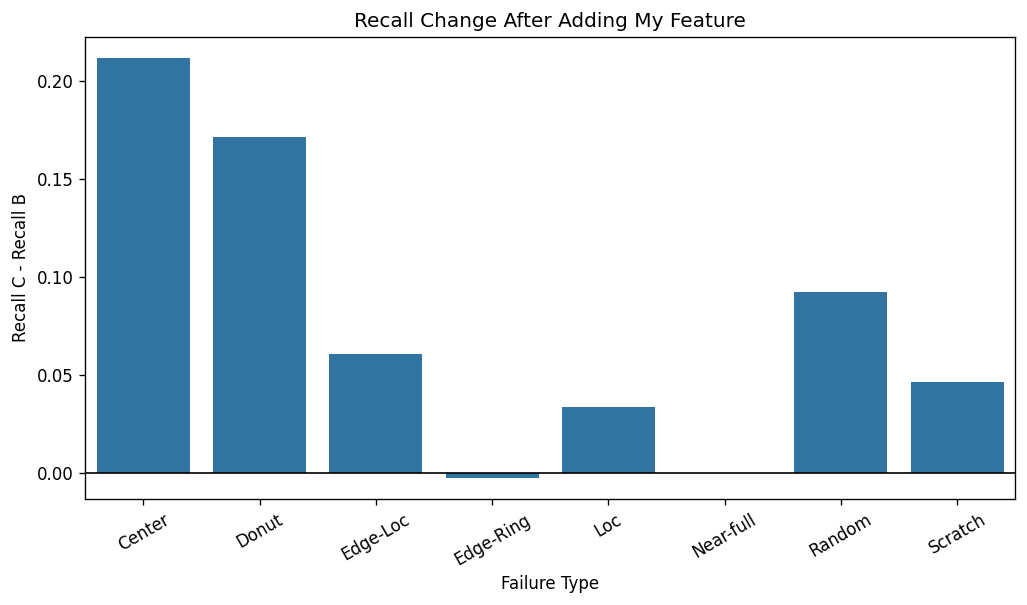

In [14]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=recall_comparison,
    x='Failure Type',
    y='Difference'
)

plt.axhline(0, color='black', linewidth=1)
plt.xticks(rotation=30)
plt.title('Recall Change After Adding My Feature')
plt.ylabel('Recall C - Recall B')
plt.show()

**Q11.**필수 기록

자신이 개선하려고 했던 불량 유형의 Recall은 어떻게 변화했나요?

처음 세운 가설과 실제 결과를 비교해 보세요.

**답변:**

**Center의 Recall은 65.31% → 86.50%로 약 21.19%p 상승**했습니다. 반면 **Edge-Ring은 91.89% → 91.63%로 약 0.26%p 하락**해, 가설은 Center에서만 확인되었습니다.

### 5. 혼동행렬로 결과 확인하기

특정 클래스의 Recall 변화가 나타났다면, 해당 유형이 어떤 유형과 혼동되었는지도 확인해 보세요.

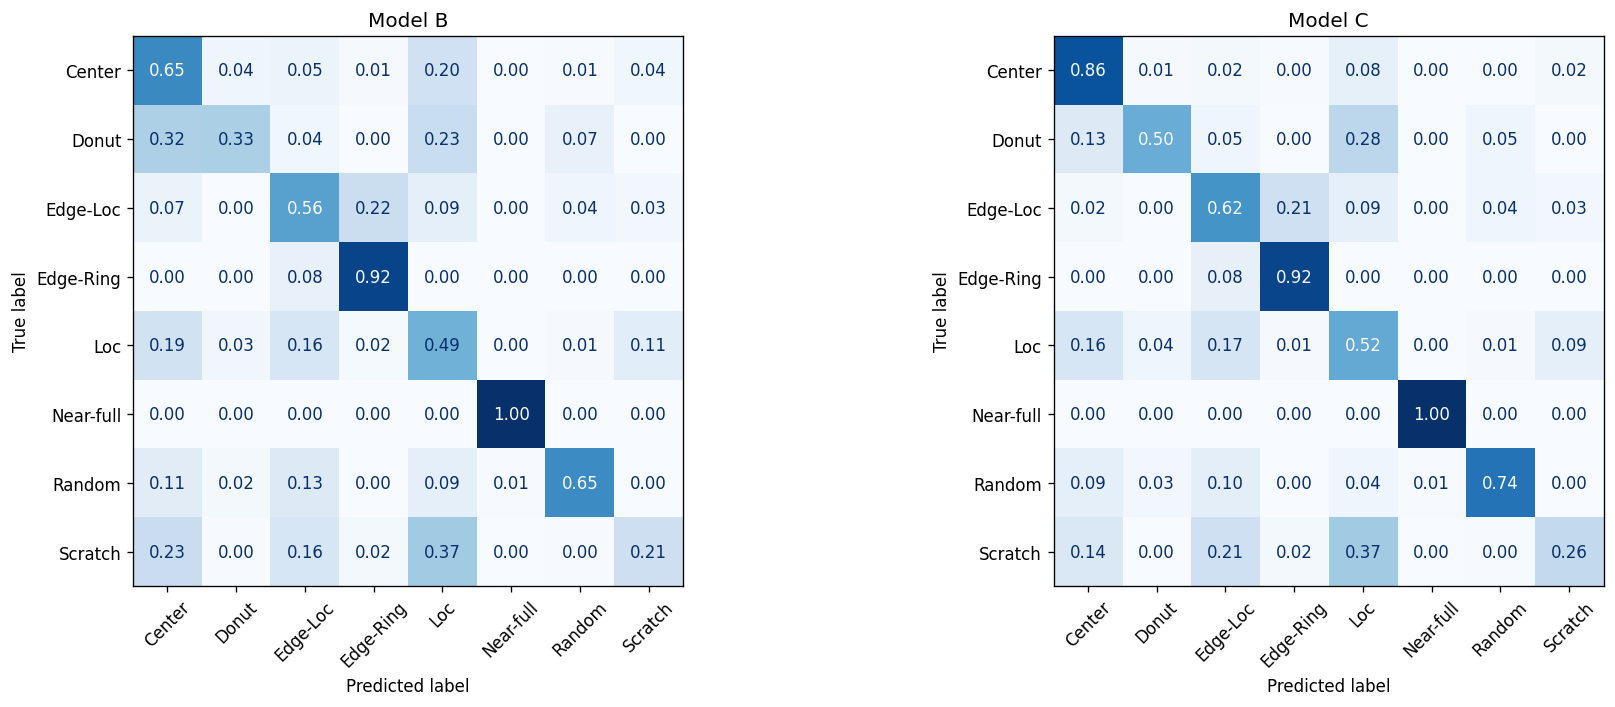

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, pred, title in zip(
    axes,
    [pred_B, pred_C],
    ['Model B', 'Model C']
):
    cm = confusion_matrix(
        y_test,
        pred,
        labels=labels,
        normalize='true'
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    disp.plot(
        ax=ax,
        cmap='Blues',
        values_format='.2f',
        colorbar=False
    )

    ax.set_title(title)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Q12.**

모델 C에서 오분류가 줄어든 유형이 있나요? 반대로 오분류가 증가한 유형도 있나요?

**답변:**

**Center, Donut, Edge-Loc, Loc, Random, Scratch**는 오분류가 줄었습니다. **Edge-Ring은 오분류가 5개 늘었고**, Near-full은 변화가 없었습니다.

### 6. 실험 결과에 대한 결론 내리기

이제 개인 실험을 마무리할 차례입니다.

**Q13.**필수 기록

나만의 특성공학 실험 결론

다음 내용을 포함하여 실험 결과를 정리해 보세요.

1. 어떤 특성을 선택했으며, 그 이유는 무엇인가요?
2. 새 특성을 어떤 방법으로 계산했나요?
3. 특성을 추가한 후 전체 분류 성능은 어떻게 변화했나요?
4. 개선을 기대했던 불량 유형에서 실제로 변화가 나타났나요?
5. 이번 실험을 통해 무엇을 알게 되었나요?

특성을 추가했는데 성능이 개선되지 않았다면 그것도 의미 있는 실험 결과입니다.

가설이 맞지 않았다는 사실을 확인하는 것도 실험의 중요한 과정입니다.

다만 그 결과가 나타난 이유를 단정하기보다는, 데이터의 특성과 모델의 분류 결과를 근거로 가능한 원인을 추론해 보세요.

**답변:**

중앙에 불량이 집중된 패턴을 구분하기 위해 중앙 영역 불량률을 선택했습니다. 중심에서 최대 거리의 40% 이내인 유효 칩 중 불량 칩의 비율로 계산했습니다. 특성을 추가하자 정확도는 약 6.07%p, Macro F1은 약 0.0770 높아졌습니다. Center의 Recall은 약 21.19%p 개선됐지만 Edge-Ring은 약 0.26%p 낮아져 가설은 일부만 맞았습니다. 새 특성은 전체 성능에 도움이 되었지만 모든 유형을 개선하지는 않았습니다. 이번 결과는 같은 분할 조건에서 얻은 값이므로 다른 분할이나 로트별 분리에서도 확인할 필요가 있습니다.

## 활동 D. 중간고사 대체 보고서 작성하기

이번 활동에서는 지금까지 진행한 실습 내용을 하나의 보고서로 정리합니다.

보고서는 단순히 실행한 코드를 모두 모아 놓는 문서가 아닙니다.

**어떤 문제를 해결하려 했고, 어떤 실험을 했으며, 어떤 결과를 얻었는지 설명하는 문서**입니다.

코드 전체를 보고서에 붙여 넣을 필요는 없습니다. 중요한 코드 일부, 표, 그래프, 분석 내용을 중심으로 작성해 보세요.

### 1. 보고서 구성

**보고서 제목: 웨이퍼맵 불량 패턴 분류 실험과 특성공학**

다음 구성을 참고하여 작성하세요.

Part 1. 웨이퍼맵 데이터와 CNN 분류

**4강에서 진행한 CNN 분류 실습**을 중심으로 정리합니다.

- 웨이퍼맵 데이터의 특징과 분류하려는 불량 유형
- CNN을 이용한 분류 실험
- 모델의 성능 평가 결과
- 오분류 사례와 그 원인에 대한 분석

4강 실습에서 저장한 결과표, 학습 그래프, 혼동행렬 등을 활용해도 됩니다.

**작성할 때 생각해 볼 질문**

CNN은 어떤 데이터를 입력받아 무엇을 예측했나요?

어떤 불량 유형을 상대적으로 잘 분류했고, 어떤 유형을 어려워했나요?

Part 2. 데이터 증강 실험

5강에서 수행한 데이터 증강 실험을 정리합니다.

- 데이터 증강을 적용한 이유
- 적용한 증강 방법
- 증강 전후 모델의 성능
- 실험 결과에 대한 해석
- 도메인 지식과 데이터 증강의 관계

특히 모델 성능이 예상과 다르게 나타났다면 그 이유를 분석해 보세요.

데이터 증강이 반드시 성능을 향상시키는 것은 아닙니다.

이번에 배운 실험 조건 통제의 관점에서 기존 증강 실험의 한계를 생각해 보아도 좋습니다.

Part 3. 공통 특성공학 실험

미션 01과 미션 02의 결과를 활용합니다.

- 웨이퍼맵에서 추출한 공통 특성
- 특성의 계산 방법과 의미
- 기준 모델 A와 비교 모델 B의 실험 조건
- 특성 추가 전후의 성능 비교
- 혼동행렬 및 클래스별 분류 결과 분석

**핵심 질문**

가장자리 불량률을 추가한 것이 실제로 분류 성능에 도움이 되었나요?

Part 4. 개인 특성공학 실험

이번 미션에서 직접 수행한 개인 실험입니다.

- 새로운 특성의 이름과 선택 이유
- 특성 설계 가설
- 특성 추출 방법과 구현 코드
- 새 특성의 분포 및 특징
- 모델 B와 모델 C의 성능 비교
- 가설과 실험 결과의 비교
- 결과에 대한 해석

개인 실험에서는 **특성 설계의 타당성과 결과 해석**이 중요합니다.

새로운 특성이 분류 성능을 향상시키지 못했더라도 불이익이 있는 것은 아닙니다.

자신이 어떤 가설을 세웠고, 어떤 실험을 통해 무엇을 확인했는지 설명해 보세요.

Part 5. 종합 결론

지금까지의 실험을 종합하여 자신의 생각을 정리합니다.

다음 질문을 참고하세요.

- CNN과 특성 기반 분류 모델은 어떤 차이가 있나요?
- 데이터 증강과 특성공학은 각각 어떤 목적으로 사용하나요?
- 도메인 지식은 이번 실습에서 어떤 역할을 했나요?
- 실험 조건을 동일하게 유지하는 것이 왜 중요한가요?
- 앞으로 분류 성능을 개선한다면 어떤 방법을 시도하고 싶은가요?

모든 질문에 개별적으로 답할 필요는 없습니다.

가장 중요하다고 생각한 내용을 연결하여 하나의 결론으로 작성해 보세요.

### 2. 보고서 작성 시 유의 사항

**① 모든 워크북 질문에 답할 필요는 없습니다.**

워크북의 질문은 실습 과정에서 코드를 이해하고 결과를 해석하기 위한 학습 활동입니다.

보고서에는 각 미션의 **[필수 기록]** 질문을 중심으로 필요한 내용을 정리하세요.

질문에 대한 답변을 그대로 나열하기보다 보고서의 흐름에 맞게 재구성해도 됩니다.

**② 실험 결과는 실제 출력값을 사용하세요.**

모델의 정확도나 F1-score가 높지 않아도 괜찮습니다.

결과를 임의로 수정하거나 여러 실험 중 좋은 결과만 선택하여 기록하지 마세요.

**③ 결과에 대한 자신의 해석을 포함하세요.**

예를 들어 다음 두 문장을 비교해 보세요.

- "새로운 특성을 추가하자 정확도가 0.02 상승했다."
- "새로운 특성을 추가하자 정확도가 0.02 상승했다. 특히 Edge-Loc의 Recall이 높아졌으며, 이는 추가한 특성이 가장자리 일부에 집중된 불량 분포를 표현하는 데 도움이 되었을 가능성을 보여준다."

두 번째 문장은 실험 결과를 구체적인 분석과 연결합니다.

다만 실험 결과만으로 성능 변화의 원인을 완전히 증명한 것은 아니므로, 추론과 확인된 사실을 구분하여 작성하세요.

**④ 표와 그래프를 적극적으로 활용하세요.**

실험 결과를 설명하는 데 필요한 표와 그래프를 포함하면 좋습니다.

단, 그래프를 넣는 것에서 끝내지 말고 **그래프가 무엇을 보여주는지** 설명하세요.

**⑤ 기존 실습 결과를 재사용해도 됩니다.**

Part 1과 Part 2는 이미 수행한 실습 내용을 정리하는 영역입니다.

모델을 처음부터 다시 학습할 필요는 없습니다. 이전 실습에서 저장한 결과를 활용하세요.

## 미션 03 결과 정리

이번 미션에서는 직접 설계한 특성을 모델에 추가하고 기존 모델과 비교했습니다.

| 실험 | 입력 특성 | 목적 |
| --- | --- | --- |
| 모델 A | defect_ratio | 기준 모델 |
| 모델 B | defect_ratio, edge_ratio | 공통 특성 추가 효과 확인 |
| 모델 C | defect_ratio, edge_ratio, my_feature | 개인 특성 추가 효과 확인 |

모델 C의 성능이 가장 높았을 수도 있고, 모델 B보다 낮았을 수도 있습니다.

중요한 것은 어떤 결과가 나왔는지보다 **그 결과를 통해 무엇을 알게 되었는가**입니다.

### 완료 확인

- 기존 모델의 오분류 결과를 확인했다.
- 새로운 특성의 이름과 선택 이유를 작성했다.
- 특성의 효과에 대한 가설을 세웠다.
- 새로운 특성을 계산하는 함수를 구현했다.
- 특성값의 범위와 분포를 확인했다.
- 기존 모델 B와 개인 모델 C를 동일한 조건에서 비교했다.
- 정확도와 Macro F1-score의 변화를 분석했다.
- 클래스별 분류 성능 변화를 확인했다.
- 개인 실험의 결론을 작성했다.
- 기존 실습 결과를 포함한 중간고사 대체 보고서를 완성했다.

### 보고서에 반드시 포함할 내용

앞선 미션을 포함하여 다음 내용을 확인하세요.

1. 기존 CNN 분류 결과와 오분류 분석
2. 데이터 증강 실험 결과와 해석
3. 공통 특성공학 실험의 성능 비교
4. 개인 특성의 설계 이유와 구현 방법
5. 개인 특성 추가 전후의 성능 비교
6. 실험 결과에 대한 종합 결론

### 마지막으로 생각해 보기

이번 프로젝트에서는 같은 웨이퍼맵 데이터를 여러 방법으로 분석했습니다.

CNN은 이미지에서 특징을 학습했고, 특성공학에서는 사람이 직접 의미 있는 정보를 추출했습니다.

우리는 모델을 학습시키는 것뿐 아니라, **왜 이런 결과가 나타났는지 질문하고 실험으로 확인하는 과정**도 경험했습니다.

실제 산업 현장에서 AI 모델을 활용할 때도 중요한 것은 단순히 높은 정확도만 얻는 것이 아닙니다.

데이터의 특성을 이해하고, 실험 조건을 통제하고, 결과를 신뢰할 수 있는지 검토해야 합니다.

**좋은 AI 모델을 만드는 과정은 좋은 질문을 만드는 것에서 시작됩니다.**